In [1]:
!nvidia-smi

Thu Nov  5 11:09:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
REPO_URL = 'https://github.com/VladislavZherikhov/DLCV_course_project.git'
%cd /kaggle/working
!rm -rf repo && git clone -q -b cbam {REPO_URL} repo
%cd /kaggle/working/repo
!git log -1 --oneline
!pip install -q omegaconf

/kaggle/working
/kaggle/working/repo
08f769c (HEAD -> cbam, origin/cbam) Add CBAM attention module


In [3]:
!python -u main.py general.debug=true model.attention=cbam

11:09:41 | Experiment: resnet18_224_debug
11:09:41 | Output dir: /kaggle/working/outputs/resnet18_224_debug
11:09:41 | System: {"python": "3.13.16", "torch": "2.11.0+cu130", "cuda_available": true, "cpu_count": 4, "gpu": "Tesla T4", "gpu_count": 2, "gpu_memory_gb": 14.6, "cuda": "13.0"}
11:09:41 | Config:
general:
  exp_name: resnet18_224
  seed: 42
  debug: true
  debug_samples: 128
paths:
  data_root: /kaggle/input
  out_dir: /kaggle/working/outputs
data:
  smoke_id: 0
  fire_id: 1
  val_size: 0.15
  img_size: 224
model:
  name: resnet18
  pretrained: true
  attention: cbam
  cbam:
    reduction: 16
    kernel_size: 7
    identity_init: true
training:
  epochs: 15
  batch_size: 64
  lr: 0.0003
  weight_decay: 0.0001
  attention_lr_mult: 10
  mixed_precision: true
  class_weights: true
  early_stopping: 5
  monitor: f1_macro
  num_workers: 4
  progress_bar: false
logging:
  log_interval: 50
  n_error_examples: 24
  zip_outputs: true

11:21:54 | Data root: /kaggle/input (parsed in 733.

In [4]:
EXP_NAME = 'resnet18_cbam_224'
!python -u main.py general.exp_name={EXP_NAME} model.attention=cbam

11:22:40 | Experiment: resnet18_cbam_224
11:22:40 | Output dir: /kaggle/working/outputs/resnet18_cbam_224
11:22:41 | System: {"python": "3.13.16", "torch": "2.11.0+cu130", "cuda_available": true, "cpu_count": 4, "gpu": "Tesla T4", "gpu_count": 2, "gpu_memory_gb": 14.6, "cuda": "13.0"}
11:22:41 | Config:
general:
  exp_name: resnet18_cbam_224
  seed: 42
  debug: false
  debug_samples: 128
paths:
  data_root: /kaggle/input
  out_dir: /kaggle/working/outputs
data:
  smoke_id: 0
  fire_id: 1
  val_size: 0.15
  img_size: 224
model:
  name: resnet18
  pretrained: true
  attention: cbam
  cbam:
    reduction: 16
    kernel_size: 7
    identity_init: true
training:
  epochs: 15
  batch_size: 64
  lr: 0.0003
  weight_decay: 0.0001
  attention_lr_mult: 10
  mixed_precision: true
  class_weights: true
  early_stopping: 5
  monitor: f1_macro
  num_workers: 4
  progress_bar: false
logging:
  log_interval: 50
  n_error_examples: 24
  zip_outputs: true

11:22:54 | Data root: /kaggle/input (parsed in 

TEST (4306 images)

accuracy             0.9322
precision_macro      0.8895
recall_macro         0.8900
f1_macro             0.8898
roc_auc_macro        0.9792
precision_weighted   0.9323
recall_weighted      0.9322
f1_weighted          0.9322
roc_auc_weighted     0.9875

Per-class metrics:
            precision  recall      f1  roc_auc  avg_precision  support
class                                                                 
none           0.9710  0.9671  0.9690   0.9941         0.9926     2005
smoke          0.9197  0.9266  0.9231   0.9847         0.9584     1186
fire           0.7636  0.7636  0.7636   0.9531         0.8047      220
fire_smoke     0.9038  0.9028  0.9033   0.9847         0.9398      895

Confusion matrix:
                 pred_none  pred_smoke  pred_fire  pred_fire_smoke
true_none             1939          49          4               13
true_smoke              48        1099          5               34
true_fire                8           5        168             

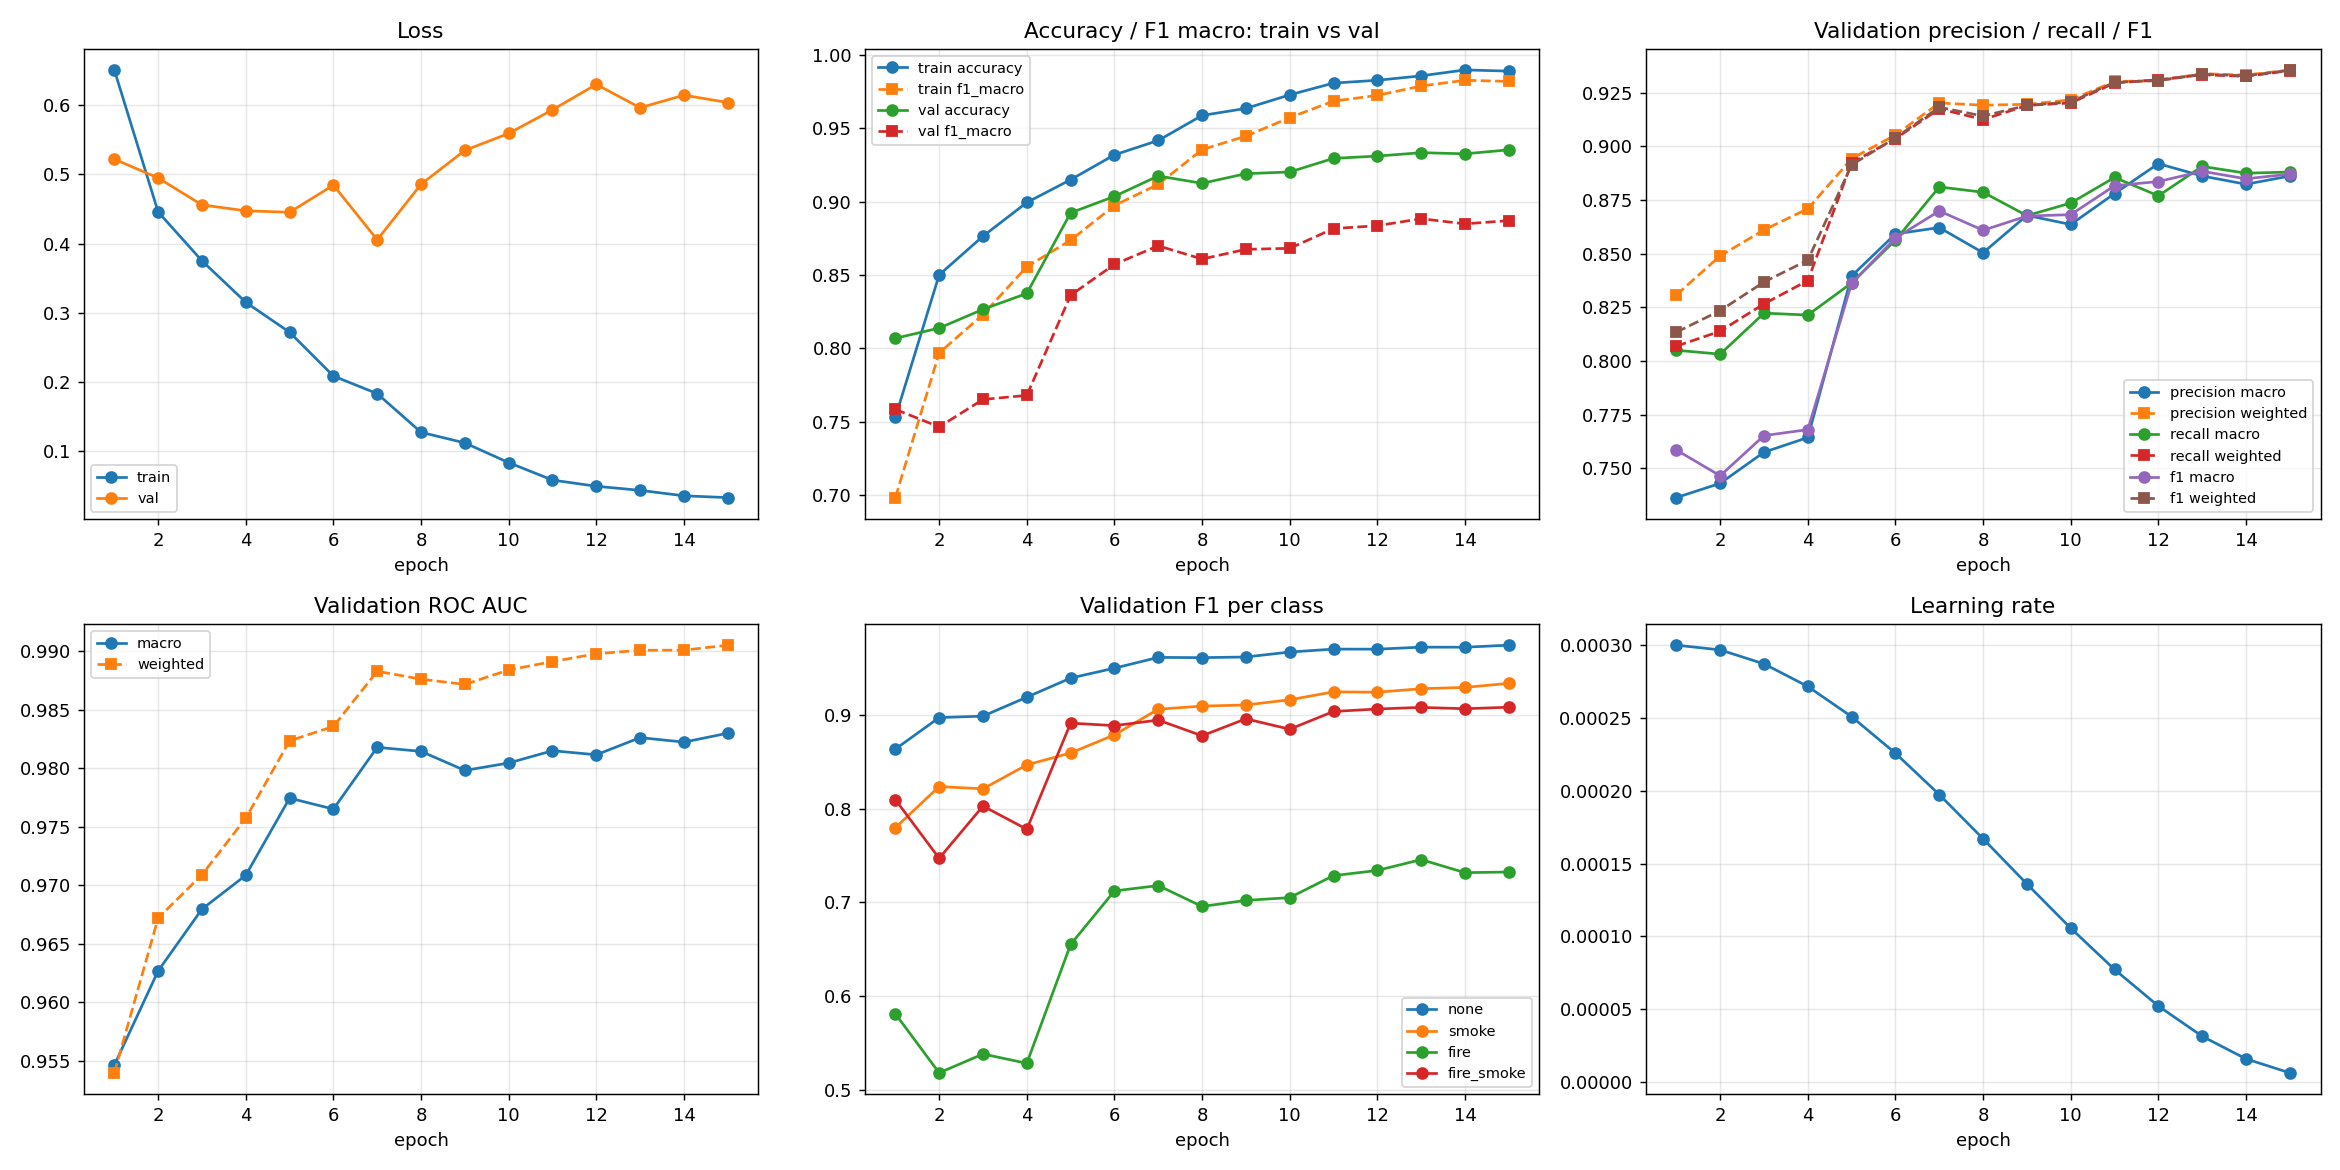

test_confusion_matrix.png


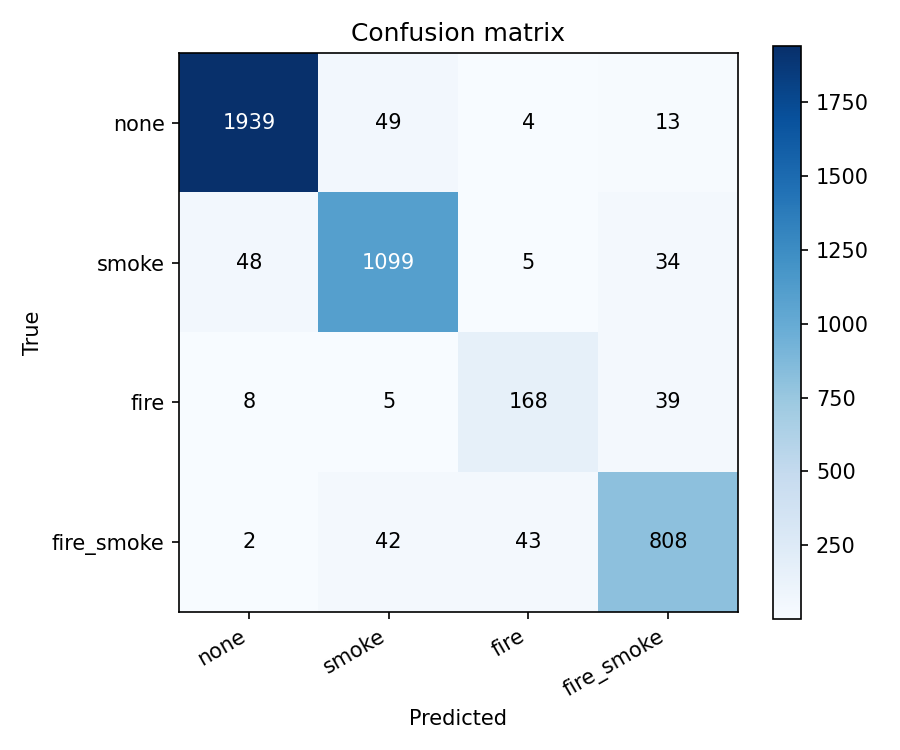

test_confusion_matrix_norm.png


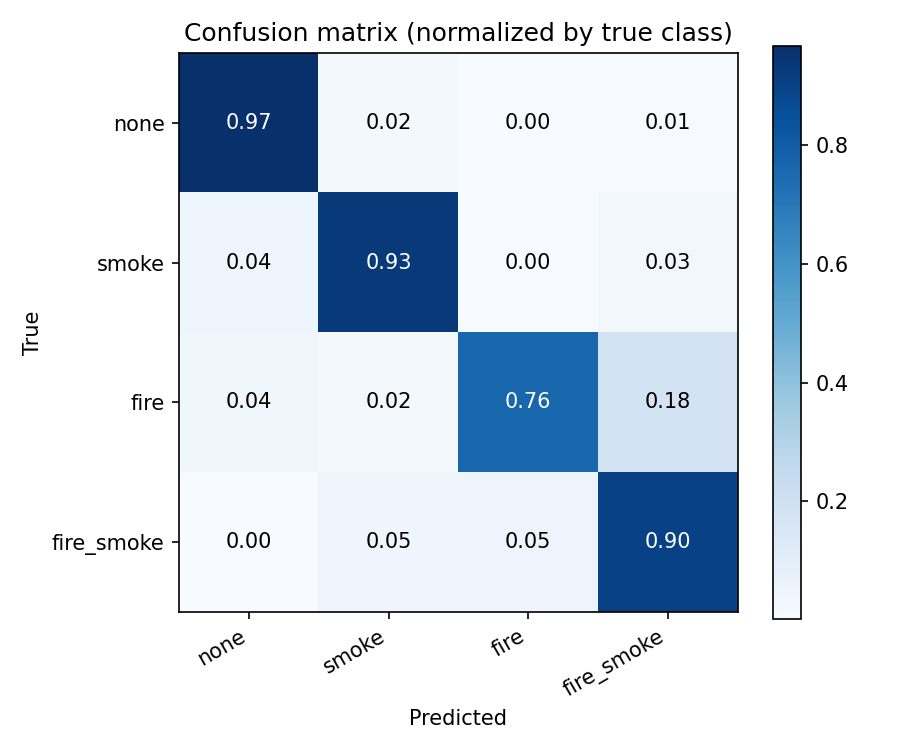

test_roc_pr_curves.png


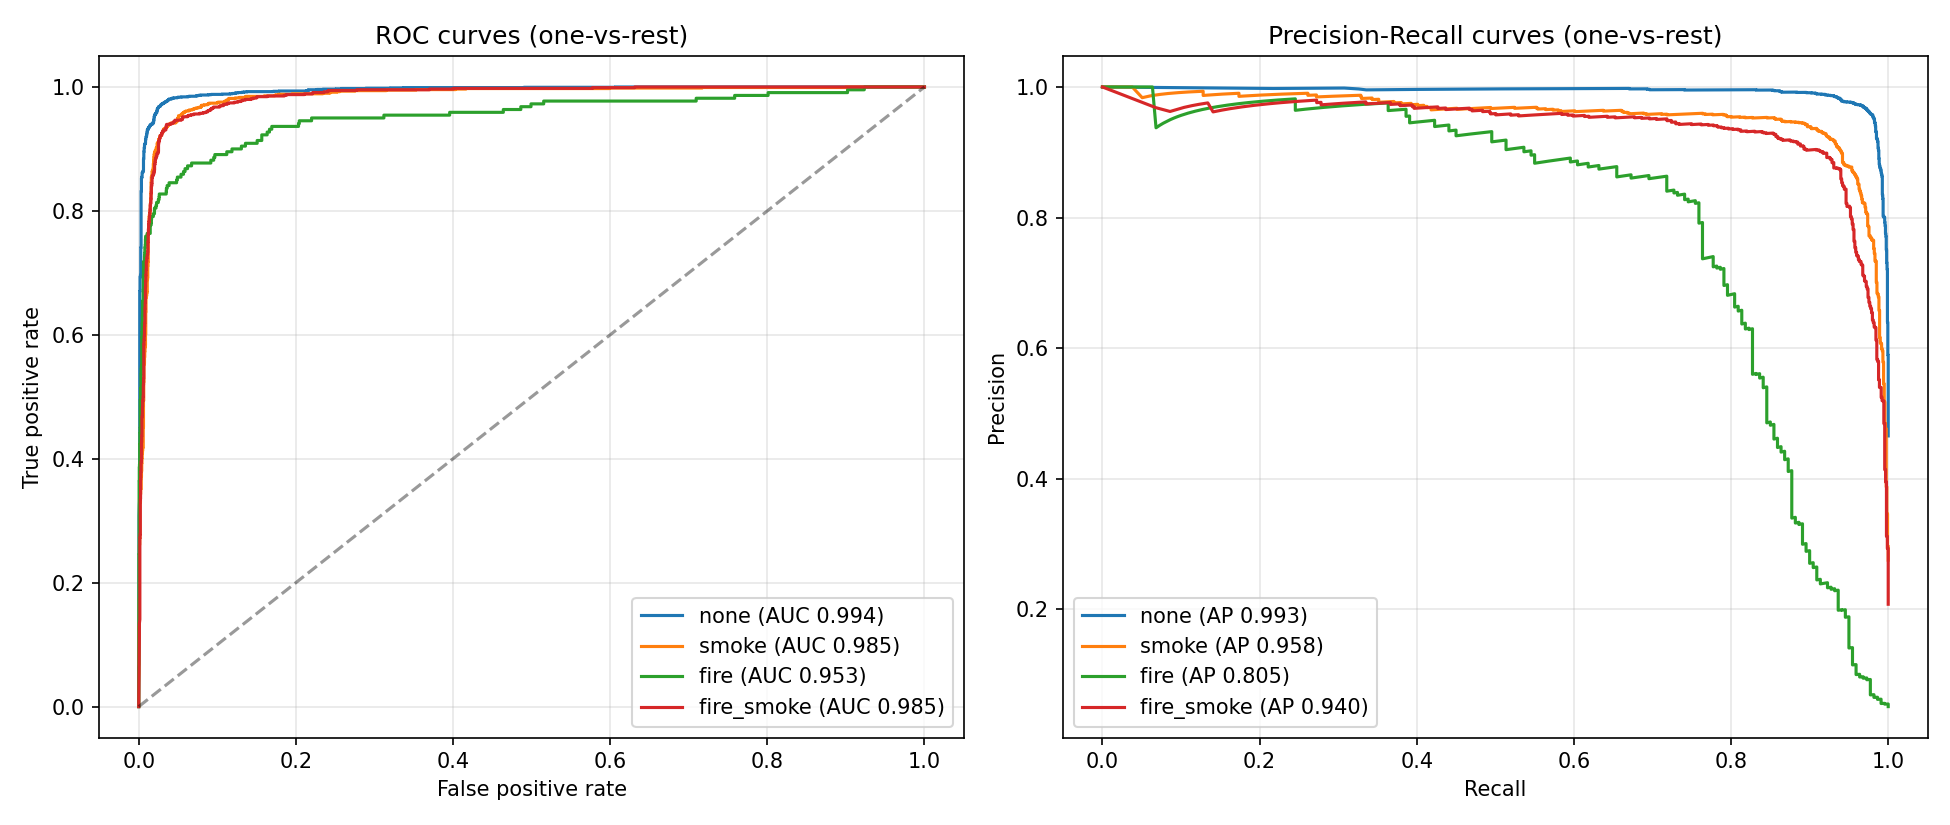

test_errors.png


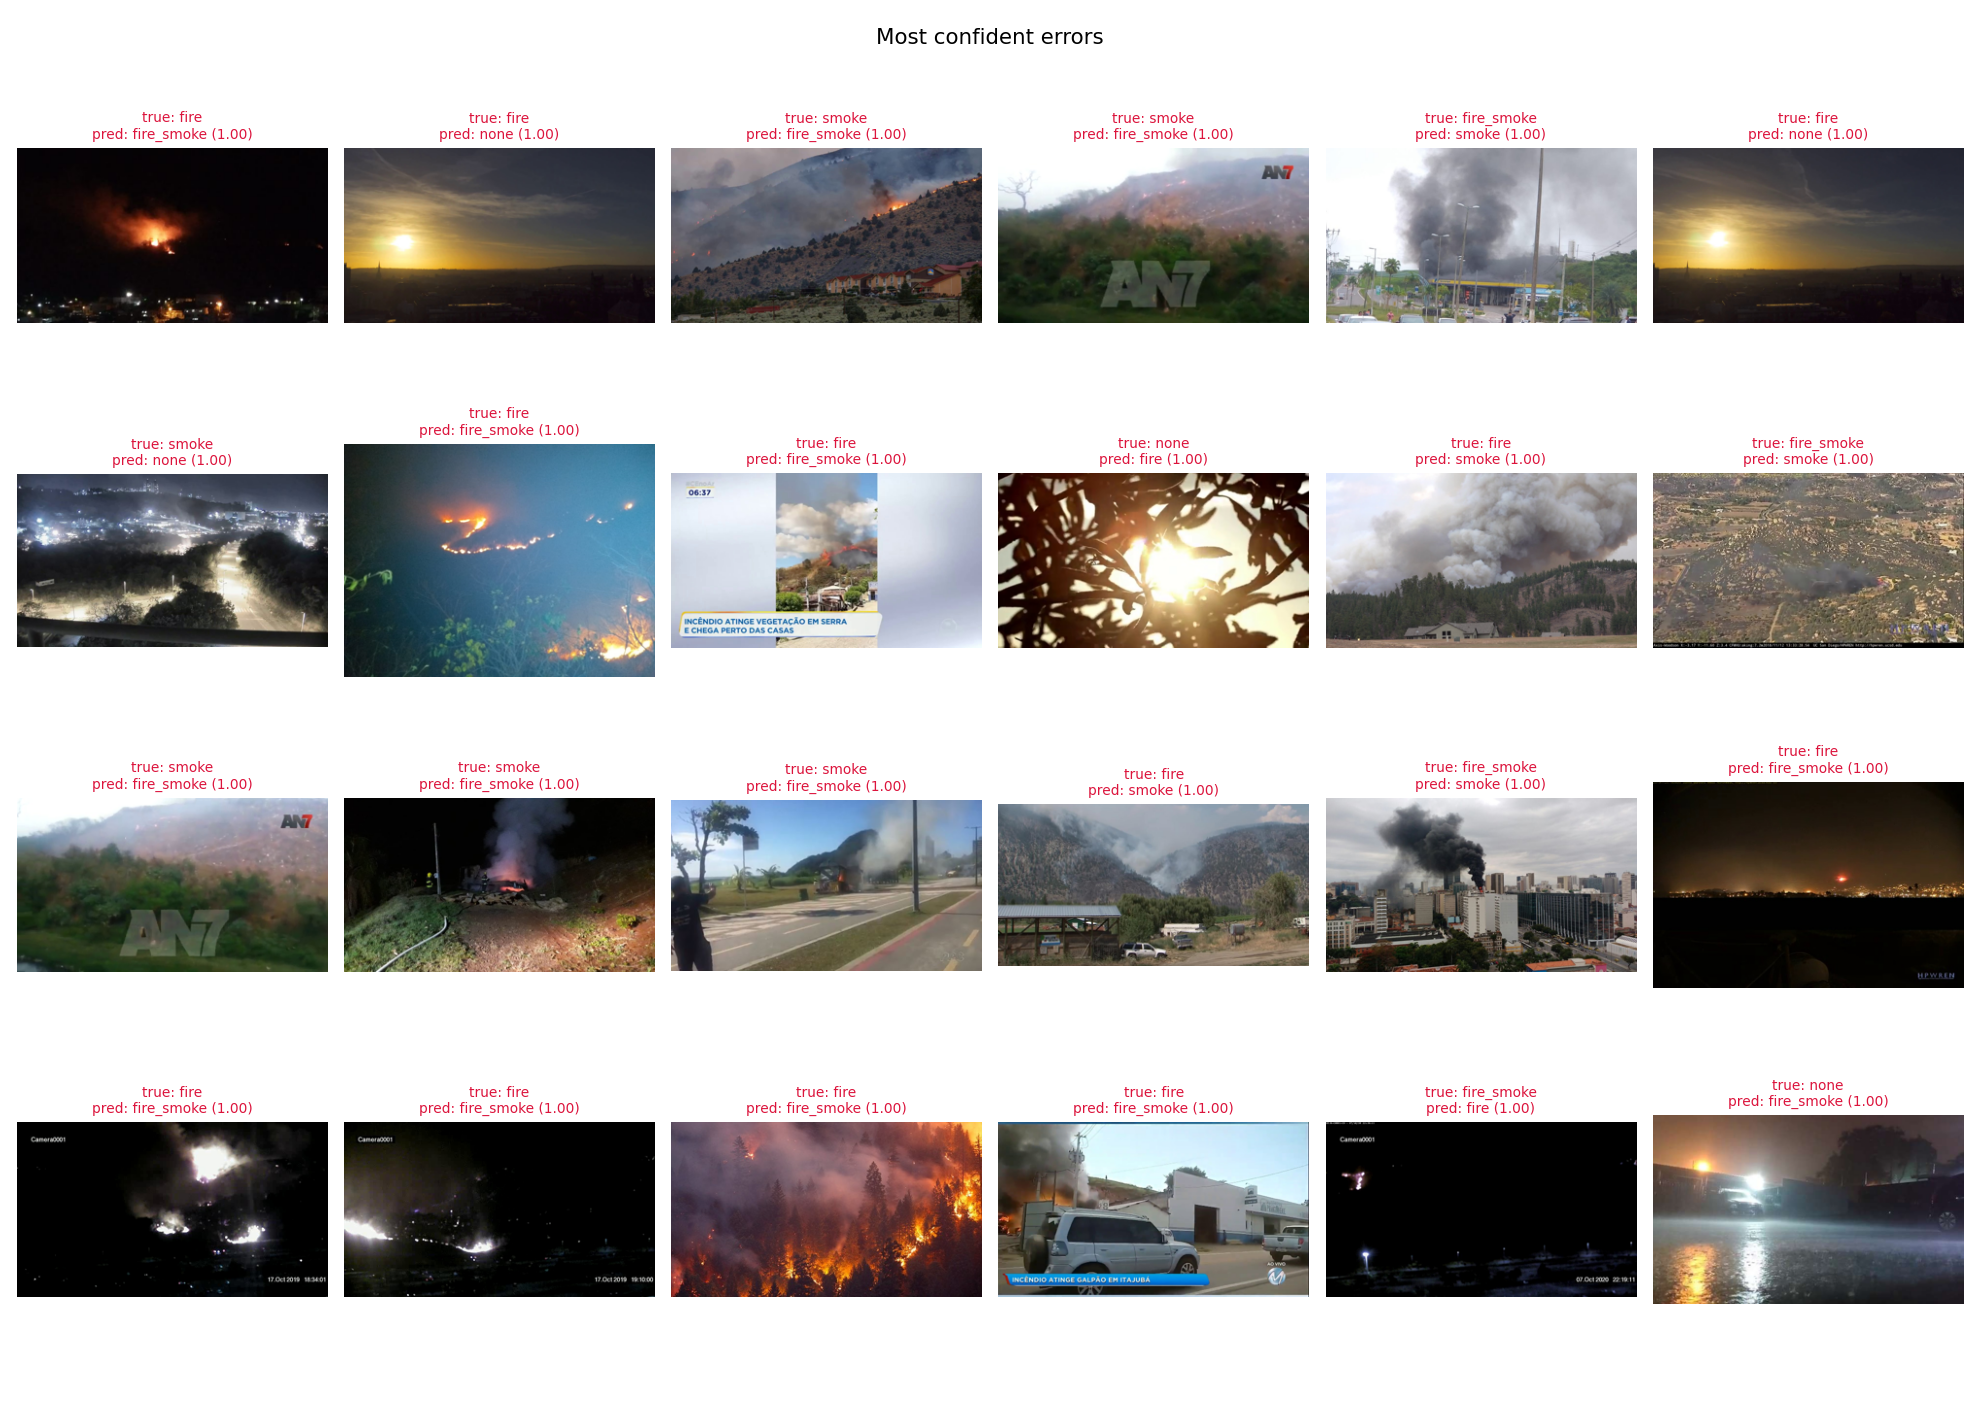

,epoch,lr,epoch_time_s,gpu_mem_gb,train_loss,train_accuracy,train_precision_macro,train_recall_macro,train_f1_macro,train_roc_auc_macro,...,val_f1_none,val_precision_smoke,val_recall_smoke,val_f1_smoke,val_precision_fire,val_recall_fire,val_f1_fire,val_precision_fire_smoke,val_recall_fire_smoke,val_f1_fire_smoke
0,1,0.000300,316.1,1.17,0.651297,0.752947,0.685608,0.748154,0.698266,0.928578,...,0.863469,0.754667,0.806268,0.779614,0.462500,0.781690,0.581152,0.785358,0.835398,0.809605
1,2,0.000297,86.3,1.17,0.445790,0.850123,0.781048,0.835658,0.796882,0.968034,...,0.897091,0.829480,0.817664,0.823529,0.372308,0.852113,0.518201,0.854214,0.663717,0.747012
2,3,0.000287,86.0,1.17,0.375060,0.876508,0.806102,0.861322,0.823075,0.977355,...,0.898640,0.821683,0.820513,0.821098,0.390476,0.866197,0.538293,0.890086,0.730973,0.802721
3,4,0.000272,85.4,1.17,0.315002,0.899465,0.838301,0.885930,0.855669,0.984010,...,0.918849,0.872920,0.821937,0.846662,0.382911,0.852113,0.528384,0.874172,0.700885,0.777996
4,5,0.000251,85.2,1.17,0.271690,0.915022,0.856246,0.904607,0.873738,0.988023,...,0.939231,0.933222,0.796296,0.859339,0.641892,0.669014,0.655172,0.870152,0.913274,0.891192
5,6,0.000226,85.0,1.17,0.208321,0.931949,0.880775,0.922850,0.897397,0.992595,...,0.949784,0.846764,0.913105,0.878684,0.727941,0.697183,0.712230,0.895683,0.881416,0.888492
6,7,0.000197,85.1,1.17,0.182823,0.941749,0.896110,0.934034,0.911893,0.994396,...,0.961279,0.934848,0.878917,0.906021,0.658824,0.788732,0.717949,0.904159,0.884956,0.894454
7,8,0.000167,85.1,1.17,0.126892,0.958813,0.921587,0.953893,0.935526,0.997171,...,0.961005,0.871895,0.950142,0.909339,0.622222,0.788732,0.695652,0.928854,0.831858,0.877684
8,9,0.000136,85.1,1.17,0.111512,0.963610,0.932356,0.960246,0.944704,0.997621,...,0.961702,0.930163,0.891738,0.910545,0.707143,0.697183,0.702128,0.872483,0.920354,0.895780
9,10,0.000106,85.1,1.17,0.082992,0.972862,0.945546,0.971449,0.957289,0.998699,...,0.966995,0.899725,0.933048,0.916084,0.679739,0.732394,0.705085,0.900917,0.869027,0.884685


In [5]:
import pandas as pd
from IPython.display import Image, display
EXP = f'/kaggle/working/outputs/{EXP_NAME}'
print(open(f'{EXP}/test_report.txt').read())
for name in ['training_curves.png', 'test_confusion_matrix.png', 'test_confusion_matrix_norm.png',
             'test_roc_pr_curves.png', 'test_errors.png']:
    print(name); display(Image(f'{EXP}/{name}'))
display(pd.read_csv(f'{EXP}/log.csv'))